# Análise do Target

O target definido é o Ever 90 em 12 meses, classificando como Bad contratos com atraso superior a 90 dias em até um ano após a decisão. 

A base total soma 103.454 contratos com 4.302 Bads (4,16%), sendo 2.795 no treino (2017-2022). 

O indicador apresenta estabilidade histórica (variação de 3,59% a 4,20%) e alta gravidade, com 57,5% dos Bads ultrapassando 180 dias de atraso. 

A janela de 12 meses captura 87% da inadimplência observada em 18 meses, mantendo recência de dados até 2024 e superando o critério Over, que identifica apenas 70% dos casos. O roll rate confirma a baixa recuperação após 120 dias de atraso (6%).


## Definições

**Atraso (dias)**: quitação (ou corte) menos data prevista. 

**Janela de n meses**: parcelas vencendo até `data_decisao` + n meses (~11 meses efetivos). 

**Ever X**: maior atraso histórico na janela superou X dias. 

**Over X**: maior atraso em aberto em uma data de referência superou X dias. 

**População**: contratos aprovados e consistentes com janela completa até a 

**Data de corte** (22/02/2025).


In [1]:

import pandas as pd
import numpy as np
import sqlite3 
from contextlib import closing
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

db_path = "../../data/processed/database.db"

In [2]:

def read_sql_file(path):
    with open(path, 'r', encoding='utf-8') as f:
        return f.read()

def run_query(path, params=None):
    sql = read_sql_file(path)
    with closing(sqlite3.connect(db_path)) as conn:
        return pd.read_sql_query(sql, conn, params=params)


## Configuração

As consultas .sql são executadas via notebook no banco data/processed/database.db, utilizando a data_corte 2025-02-22 e janelas de performance de 1, 3, 6, 9, 12 e 18 meses. 

O arquivo bad_rate.sql consolida os indicadores max_ever e max_over por contrato, enquanto roll_rate_ever.sql e roll_rate_over.sql detalham a transição de atraso por faixa, baseando-se no maior atraso por parcela e no critério Over, respectivamente.


## Bad Rate


**Pergunta:** se o Bad for definido como atraso acima de X dias nos n meses seguintes à decisão, quantos contratos viram Bad, o número é estável entre safras e a janela é madura?

**Método (`bad_rate.sql`):** para cada contrato, o Ever é o maior atraso entre as parcelas da janela (até quitação ou data de corte), e o Over é o maior atraso aberto nas datas de referência. Os cortes são aninhados. Verificado: `Over ≤ Ever` em todos os contratos.

In [60]:

conn = sqlite3.connect(db_path)

cur = conn.cursor()

bad_rate_1_df = run_query('bad_rate.sql', params = {"data_corte": "2025-02-22", "n_meses": 1})
bad_rate_3_df = run_query('bad_rate.sql', params = {"data_corte": "2025-02-22", "n_meses": 3})
bad_rate_6_df = run_query('bad_rate.sql', params = {"data_corte": "2025-02-22", "n_meses": 6})
bad_rate_9_df = run_query('bad_rate.sql', params = {"data_corte": "2025-02-22", "n_meses": 9})
bad_rate_12_df = run_query('bad_rate.sql', params = {"data_corte": "2025-02-22", "n_meses": 12})
bad_rate_18_df = run_query('bad_rate.sql', params = {"data_corte": "2025-02-22", "n_meses": 18})


conn.close()


In [61]:

def bad_rate(bad_rate_df, cortes=(30, 60, 90, 120)):
    g = bad_rate_df.groupby('ano_decisao')
    out = pd.DataFrame({'contratos': g.size()})
    for tipo, col in [('ever', 'max_ever'), ('over', 'max_over')]:
        for x in cortes:
            bad = (bad_rate_df[col] > x).groupby(bad_rate_df['ano_decisao'])
            out[f'bad_{tipo}_{x}'] = bad.sum().astype(int)
            out[f'bad_rate_dft_{tipo}_{x}'] = (100 * bad.mean()).round(2)
        bad = (bad_rate_df[col] >= 180).groupby(bad_rate_df['ano_decisao'])        # teto de 180
        out[f'bad_{tipo}_180'] = bad.sum().astype(int)
        out[f'bad_rate_dft_{tipo}_180'] = (100 * bad.mean()).round(2)
    return out

In [62]:

bad_rate_1_df['data_decisao'] = pd.to_datetime(bad_rate_1_df['data_decisao'])

bad_rate_1_df['ano_decisao'] = bad_rate_1_df['data_decisao'].dt.year

tabela = bad_rate(bad_rate_1_df)
total = bad_rate_1_df.assign(ano_decisao='Total')                            # linha de total
tabela = pd.concat([tabela, bad_rate(total)])

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(tabela)


,contratos,bad_ever_30,bad_rate_dft_ever_30,bad_ever_60,bad_rate_dft_ever_60,bad_ever_90,bad_rate_dft_ever_90,bad_ever_120,bad_rate_dft_ever_120,bad_ever_180,bad_rate_dft_ever_180,bad_over_30,bad_rate_dft_over_30,bad_over_60,bad_rate_dft_over_60,bad_over_90,bad_rate_dft_over_90,bad_over_120,bad_rate_dft_over_120,bad_over_180,bad_rate_dft_over_180
ano_decisao,,,,,,,,,,,,,,,,,,,,,
2017,557,4,0.72,4,0.72,4,0.72,4,0.72,4,0.72,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2018,1552,37,2.38,12,0.77,2,0.13,2,0.13,2,0.13,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2019,1520,51,3.36,20,1.32,7,0.46,1,0.07,1,0.07,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2020,1723,73,4.24,29,1.68,11,0.64,6,0.35,6,0.35,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2021,2697,60,2.22,23,0.85,15,0.56,9,0.33,9,0.33,1,0.04,0,0.0,0,0.0,0,0.0,0,0.0
2022,5238,68,1.30,34,0.65,16,0.31,11,0.21,11,0.21,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2023,7304,106,1.45,74,1.01,46,0.63,27,0.37,27,0.37,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2024,7963,177,2.22,105,1.32,62,0.78,30,0.38,17,0.21,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0
2025,167,0,0.00,0,0.00,0,0.00,0,0.00,0,0.00,0,0.00,0,0.0,0,0.0,0,0.0,0,0.0


In [63]:

bad_rate_3_df['data_decisao'] = pd.to_datetime(bad_rate_3_df['data_decisao'])

bad_rate_3_df['ano_decisao'] = bad_rate_3_df['data_decisao'].dt.year

tabela = bad_rate(bad_rate_3_df)
total = bad_rate_3_df.assign(ano_decisao='Total')                            # linha de total
tabela = pd.concat([tabela, bad_rate(total)])

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(tabela)


,contratos,bad_ever_30,bad_rate_dft_ever_30,bad_ever_60,bad_rate_dft_ever_60,bad_ever_90,bad_rate_dft_ever_90,bad_ever_120,bad_rate_dft_ever_120,bad_ever_180,bad_rate_dft_ever_180,bad_over_30,bad_rate_dft_over_30,bad_over_60,bad_rate_dft_over_60,bad_over_90,bad_rate_dft_over_90,bad_over_120,bad_rate_dft_over_120,bad_over_180,bad_rate_dft_over_180
ano_decisao,,,,,,,,,,,,,,,,,,,,,
2017,6574,131,1.99,93,1.41,71,1.08,37,0.56,37,0.56,67,1.02,19,0.29,0,0.00,0,0.0,0,0.0
2018,10458,388,3.71,197,1.88,109,1.04,61,0.58,61,0.58,158,1.51,26,0.25,0,0.00,0,0.0,0,0.0
2019,9817,419,4.27,200,2.04,92,0.94,47,0.48,47,0.48,147,1.50,37,0.38,0,0.00,0,0.0,0,0.0
2020,11039,467,4.23,250,2.26,106,0.96,54,0.49,54,0.49,193,1.75,37,0.34,0,0.00,0,0.0,0,0.0
2021,13130,496,3.78,269,2.05,117,0.89,72,0.55,71,0.54,182,1.39,32,0.24,1,0.01,0,0.0,0,0.0
2022,19954,650,3.26,393,1.97,197,0.99,118,0.59,115,0.58,272,1.36,54,0.27,0,0.00,0,0.0,0,0.0
2023,27303,970,3.55,644,2.36,405,1.48,220,0.81,213,0.78,455,1.67,122,0.45,0,0.00,0,0.0,0,0.0
2024,21533,1010,4.69,661,3.07,403,1.87,185,0.86,140,0.65,534,2.48,157,0.73,0,0.00,0,0.0,0,0.0
Total,119808,4531,3.78,2707,2.26,1500,1.25,794,0.66,738,0.62,2008,1.68,484,0.40,1,0.00,0,0.0,0,0.0


In [64]:


bad_rate_6_df['data_decisao'] = pd.to_datetime(bad_rate_6_df['data_decisao'])

bad_rate_6_df['ano_decisao'] = bad_rate_6_df['data_decisao'].dt.year

tabela = bad_rate(bad_rate_6_df)
total = bad_rate_6_df.assign(ano_decisao='Total')                            # linha de total
tabela = pd.concat([tabela, bad_rate(total)])

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(tabela)


,contratos,bad_ever_30,bad_rate_dft_ever_30,bad_ever_60,bad_rate_dft_ever_60,bad_ever_90,bad_rate_dft_ever_90,bad_ever_120,bad_rate_dft_ever_120,bad_ever_180,bad_rate_dft_ever_180,bad_over_30,bad_rate_dft_over_30,bad_over_60,bad_rate_dft_over_60,bad_over_90,bad_rate_dft_over_90,bad_over_120,bad_rate_dft_over_120,bad_over_180,bad_rate_dft_over_180
ano_decisao,,,,,,,,,,,,,,,,,,,,,
2017,6650,301,4.53,206,3.10,149,2.24,84,1.26,83,1.25,206,3.10,119,1.79,62,0.93,26,0.39,0,0.0
2018,10546,894,8.48,479,4.54,259,2.46,145,1.37,145,1.37,494,4.68,206,1.95,98,0.93,47,0.45,0,0.0
2019,9855,965,9.79,476,4.83,214,2.17,123,1.25,123,1.25,488,4.95,193,1.96,81,0.82,27,0.27,0,0.0
2020,11081,998,9.01,515,4.65,235,2.12,127,1.15,126,1.14,542,4.89,226,2.04,95,0.86,35,0.32,0,0.0
2021,13235,1126,8.51,574,4.34,270,2.04,159,1.20,156,1.18,595,4.50,238,1.80,102,0.77,47,0.36,0,0.0
2022,20075,1412,7.03,855,4.26,455,2.27,265,1.32,255,1.27,859,4.28,405,2.02,165,0.82,68,0.34,0,0.0
2023,27532,2079,7.55,1370,4.98,830,3.01,425,1.54,416,1.51,1366,4.96,731,2.66,358,1.30,145,0.53,0,0.0
2024,17569,1614,9.19,1082,6.16,661,3.76,314,1.79,224,1.27,1156,6.58,671,3.82,328,1.87,125,0.71,0,0.0
Total,116543,9389,8.06,5557,4.77,3073,2.64,1642,1.41,1528,1.31,5706,4.90,2789,2.39,1289,1.11,520,0.45,0,0.0


In [65]:

bad_rate_9_df['data_decisao'] = pd.to_datetime(bad_rate_9_df['data_decisao'])

bad_rate_9_df['ano_decisao'] = bad_rate_9_df['data_decisao'].dt.year

tabela = bad_rate(bad_rate_9_df)
total = bad_rate_9_df.assign(ano_decisao='Total')                            # linha de total
tabela = pd.concat([tabela, bad_rate(total)])

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(tabela)


,contratos,bad_ever_30,bad_rate_dft_ever_30,bad_ever_60,bad_rate_dft_ever_60,bad_ever_90,bad_rate_dft_ever_90,bad_ever_120,bad_rate_dft_ever_120,bad_ever_180,bad_rate_dft_ever_180,bad_over_30,bad_rate_dft_over_30,bad_over_60,bad_rate_dft_over_60,bad_over_90,bad_rate_dft_over_90,bad_over_120,bad_rate_dft_over_120,bad_over_180,bad_rate_dft_over_180
ano_decisao,,,,,,,,,,,,,,,,,,,,,
2017,6671,426,6.39,297,4.45,212,3.18,125,1.87,124,1.86,325,4.87,214,3.21,133,1.99,74,1.11,39,0.58
2018,10568,1230,11.64,658,6.23,356,3.37,208,1.97,207,1.96,781,7.39,388,3.67,217,2.05,120,1.14,67,0.63
2019,9858,1421,14.41,713,7.23,320,3.25,185,1.88,184,1.87,809,8.21,364,3.69,181,1.84,100,1.01,55,0.56
2020,11096,1411,12.72,764,6.89,345,3.11,195,1.76,192,1.73,870,7.84,407,3.67,202,1.82,110,0.99,63,0.57
2021,13262,1554,11.72,823,6.21,386,2.91,222,1.67,212,1.60,926,6.98,432,3.26,238,1.79,139,1.05,81,0.61
2022,20120,2009,9.99,1223,6.08,647,3.22,371,1.84,352,1.75,1307,6.50,702,3.49,381,1.89,219,1.09,129,0.64
2023,27613,2816,10.20,1856,6.72,1124,4.07,583,2.11,563,2.04,2054,7.44,1219,4.41,697,2.52,355,1.29,231,0.84
2024,11337,1314,11.59,853,7.52,529,4.67,263,2.32,201,1.77,984,8.68,649,5.72,385,3.40,196,1.73,124,1.09
Total,110525,12181,11.02,7187,6.50,3919,3.55,2152,1.95,2035,1.84,8056,7.29,4375,3.96,2434,2.20,1313,1.19,789,0.71


In [66]:

bad_rate_12_df['data_decisao'] = pd.to_datetime(bad_rate_12_df['data_decisao'])

bad_rate_12_df['ano_decisao'] = bad_rate_12_df['data_decisao'].dt.year

tabela = bad_rate(bad_rate_12_df)
total = bad_rate_12_df.assign(ano_decisao='Total')                            # linha de total
tabela = pd.concat([tabela, bad_rate(total)])

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(tabela)

,contratos,bad_ever_30,bad_rate_dft_ever_30,bad_ever_60,bad_rate_dft_ever_60,bad_ever_90,bad_rate_dft_ever_90,bad_ever_120,bad_rate_dft_ever_120,bad_ever_180,bad_rate_dft_ever_180,bad_over_30,bad_rate_dft_over_30,bad_over_60,bad_rate_dft_over_60,bad_over_90,bad_rate_dft_over_90,bad_over_120,bad_rate_dft_over_120,bad_over_180,bad_rate_dft_over_180
ano_decisao,,,,,,,,,,,,,,,,,,,,,
2017,6684,497,7.44,351,5.25,258,3.86,156,2.33,155,2.32,404,6.04,290,4.34,188,2.81,116,1.74,88,1.32
2018,10572,1502,14.21,816,7.72,432,4.09,263,2.49,262,2.48,979,9.26,509,4.81,299,2.83,188,1.78,152,1.44
2019,9858,1757,17.82,914,9.27,414,4.20,250,2.54,245,2.49,1079,10.95,514,5.21,273,2.77,167,1.69,127,1.29
2020,11099,1728,15.57,962,8.67,442,3.98,256,2.31,251,2.26,1106,9.96,546,4.92,295,2.66,178,1.60,131,1.18
2021,13276,1933,14.56,1060,7.98,476,3.59,278,2.09,265,2.00,1212,9.13,580,4.37,327,2.46,203,1.53,161,1.21
2022,20143,2431,12.07,1490,7.40,773,3.84,447,2.22,428,2.12,1686,8.37,937,4.65,536,2.66,328,1.63,260,1.29
2023,27659,3339,12.07,2214,8.00,1324,4.79,688,2.49,652,2.36,2553,9.23,1558,5.63,935,3.38,530,1.92,422,1.53
2024,4163,496,11.91,322,7.73,183,4.40,98,2.35,85,2.04,375,9.01,242,5.81,147,3.53,93,2.23,77,1.85
Total,103454,13683,13.23,8129,7.86,4302,4.16,2436,2.35,2343,2.26,9394,9.08,5176,5.00,3000,2.90,1803,1.74,1418,1.37


In [67]:

bad_rate_18_df['data_decisao'] = pd.to_datetime(bad_rate_18_df['data_decisao'])

bad_rate_18_df['ano_decisao'] = bad_rate_18_df['data_decisao'].dt.year

tabela = bad_rate(bad_rate_18_df)
total = bad_rate_18_df.assign(ano_decisao='Total')                            # linha de total
tabela = pd.concat([tabela, bad_rate(total)])

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(tabela)

,contratos,bad_ever_30,bad_rate_dft_ever_30,bad_ever_60,bad_rate_dft_ever_60,bad_ever_90,bad_rate_dft_ever_90,bad_ever_120,bad_rate_dft_ever_120,bad_ever_180,bad_rate_dft_ever_180,bad_over_30,bad_rate_dft_over_30,bad_over_60,bad_rate_dft_over_60,bad_over_90,bad_rate_dft_over_90,bad_over_120,bad_rate_dft_over_120,bad_over_180,bad_rate_dft_over_180
ano_decisao,,,,,,,,,,,,,,,,,,,,,
2017,6693,535,7.99,373,5.57,274,4.09,167,2.50,166,2.48,440,6.57,322,4.81,233,3.48,161,2.41,156,2.33
2018,10578,1755,16.59,989,9.35,493,4.66,305,2.88,304,2.87,1206,11.40,622,5.88,399,3.77,281,2.66,264,2.50
2019,9860,2043,20.72,1117,11.33,468,4.75,287,2.91,281,2.85,1344,13.63,641,6.50,384,3.89,265,2.69,244,2.47
2020,11100,2050,18.47,1167,10.51,510,4.59,301,2.71,291,2.62,1382,12.45,695,6.26,405,3.65,268,2.41,250,2.25
2021,13288,2311,17.39,1293,9.73,562,4.23,324,2.44,309,2.33,1559,11.73,757,5.70,442,3.33,289,2.17,263,1.98
2022,20167,2889,14.33,1800,8.93,914,4.53,526,2.61,500,2.48,2095,10.39,1191,5.91,703,3.49,460,2.28,422,2.09
2023,17232,2302,13.36,1491,8.65,873,5.07,477,2.77,448,2.60,1764,10.24,1092,6.34,715,4.15,441,2.56,403,2.34
Total,88918,13885,15.62,8230,9.26,4094,4.60,2387,2.68,2299,2.59,9790,11.01,5320,5.98,3281,3.69,2165,2.43,2002,2.25


### Resultado por janela (total de 2017 a 2025)

Análise de Inadimplência: Ever e Over

As janelas de 1 e 3 meses foram descartadas para análise devido ao viés amostral e à baixa observabilidade de atrasos longos, com apenas 137 casos de Ever > 90 na janela inicial. 

Observa-se que a população total reduz conforme a janela aumenta, passando de 110.558 contratos aos 3 meses para 85.041 aos 18 meses. 

No ponto de controle de 12 meses, a base conta com 95.515 contratos, apresentando um Ever > 90 dias de 3.866 casos (bad rate de 4,05%) e um Over > 90 dias de 2.687 contratos. 

Os dados demonstram consistência métrica, uma vez que o indicador Over é invariavelmente menor que o Ever, confirmando a maturação esperada das safras e a evolução dos atrasos conforme o tempo de exposição.



### Maturação da janela (safras 2017 a 2022, presentes em todas as janelas)












A análise da inadimplência grave (Ever 90) mostra que a janela de 12 meses capta 87% do atraso total observado em 18 meses (3,90% vs 4,49%). O ganho marginal por período diminui progressivamente (+27, +22, +16 e +13 pontos percentuais), confirmando que a janela de 12 meses é a mais eficiente para identificar a maior parte do risco.


### Bads disponíveis para modelar

A base de dados limitada a parcelas vencidas até 22/02/2025 apresenta subestimação do indicador Ever em safras recentes devido à censura à direita, evidenciada pela queda na conversão de atrasos de 120 para 180 dias (87% em 2024 contra >95% anteriormente) e pelo recuo artificial do Ever 90 de 5,18% em 2023Q3 para 4,40% em 2024Q1. 

Para mitigar o viés de maturação e evitar a exclusão desproporcional de contratos longos, que apresentam inadimplência superior (6,07% contra 4,50% dos curtos), a população de treino e validação foi limitada a decisões até 24/11/2023, assegurando uma janela de observação mínima de 90 dias. A análise aponta uma deriva de risco relevante em 2023, com o Ever 90 subindo de 3,84% (2022) para 4,79% (2023), tendência confirmada em trimestres já maduros e que projeta um bad rate mais elevado no teste fora do tempo em comparação ao período de treinamento.


### Gravidade: quanto de cada corte vira "não pagou"

Nas safras maduras de 2017 a 2022, o atraso superior a 90 dias mostra que 57,5% dos casos evoluem para inadimplência de longo prazo (≥ 180 dias), enquanto 41% são liquidados antes dos 120 dias. 

O indicador Ever 120 funciona como um substituto para o "não pagamento", visto que há pouca variação entre 121 e 179 dias; a dívida costuma ser quitada até o quarto mês ou permanece em aberto. Quanto à estabilidade, o corte de 90 dias apresentou a menor oscilação histórica (máx/mín de 1,17) até 2022, mas, ao considerar os dados de 2023, o corte de 120 dias torna-se o mais estável para absorver a deriva recente das safras.


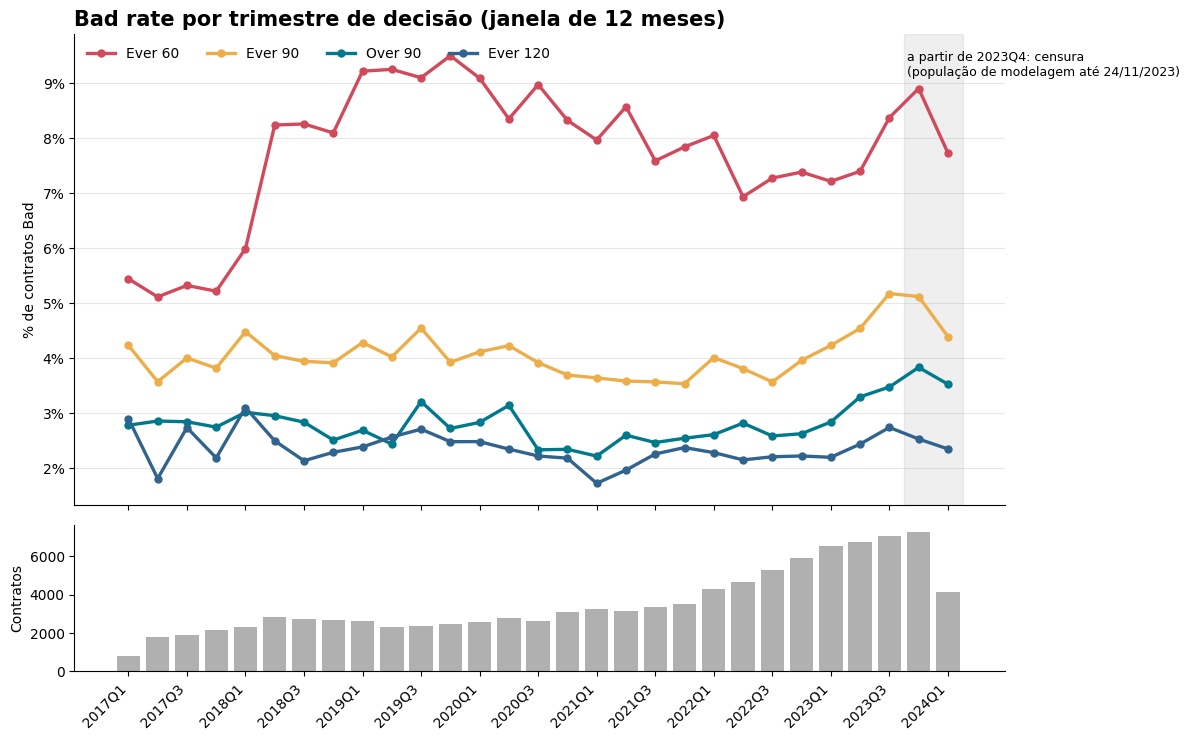

In [68]:

d = bad_rate_12_df.copy()
d['data_decisao'] = pd.to_datetime(d['data_decisao'])
d['trimestre'] = d['data_decisao'].dt.to_period('Q')

definicoes = {
    'Ever 60':  d.max_ever > 60,
    'Ever 90':  d.max_ever > 90,
    'Over 90':  d.max_over > 90,
    'Ever 120': d.max_ever > 120,
}
tri = pd.DataFrame({nome: 100 * bad.groupby(d['trimestre']).mean() for nome, bad in definicoes.items()})
n_tri = d.groupby('trimestre').size()

cores = {'Ever 60': '#d1495b', 'Ever 90': '#edae49', 'Over 90': '#00798c', 'Ever 120': '#30638e'}
x = np.arange(len(tri))

fig, (ax, ax_n) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True,
                               gridspec_kw={'height_ratios': [3.2, 1]})
for nome in tri.columns:
    ax.plot(x, tri[nome], marker='o', linewidth=2.4, markersize=5, color=cores[nome], label=nome)

if pd.Period('2023Q4') in tri.index:
    i = tri.index.get_loc(pd.Period('2023Q4'))
    ax.axvspan(i - 0.5, x[-1] + 0.5, color='grey', alpha=0.12)
    ax.text(i - 0.4, ax.get_ylim()[1] * 0.97,
            'a partir de 2023Q4: censura\n(população de modelagem até 24/11/2023)',
            va='top', fontsize=9)

ax.set_title('Bad rate por trimestre de decisão (janela de 12 meses)', loc='left', fontsize=15, fontweight='bold')
ax.set_ylabel('% de contratos Bad')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False, ncol=4, loc='upper left')

ax_n.bar(x, n_tri.values, color='#b0b0b0')
ax_n.set_ylabel('Contratos')
ax_n.set_xticks(x[::2])
ax_n.set_xticklabels([str(p) for p in tri.index[::2]], rotation=45, ha='right')

for a in (ax, ax_n):
    for lado in ['top', 'right']:
        a.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

## Roll Rate

Esta análise investiga a recuperação de contratos em atraso e o limite de probabilidade de cura, definida como a ausência de débitos após $n$ meses. 

O método utiliza snapshots mensais baseados no maior atraso aberto por contrato. 

Enquanto a métrica Over avalia apenas os fechamentos, a Ever rastreia o pagamento de cada parcela até o fim da janela. 

Ressalta-se que, devido à recorrência de contratos em múltiplos snapshots, os percentuais calculados não são estatisticamente independentes.


### Método

- **Snapshots:** fim de cada mês, por contrato, com parcela vencida e parcela ainda aberta. Cada snapshot é classificado pela **faixa de atraso inicial** (maior atraso aberto na data).
- **Cura:** o contrato não tem atraso aberto no fim da janela (n meses depois).
- **Nas duas versões** (Ever e Over), a origem e o estado final são os mesmos. Elas diferem no atraso "ever" observado na janela: o Ever acompanha cada parcela até o pagamento, o Over olha o estado nos fins de mês.
- **Na tabela Ever**, o atraso ever é truncado no fim da janela. Isso **difere do Ever do bad rate**, que não trunca. As duas tabelas medem coisas diferentes e não são comparáveis.
- Cada coluna "ever" só vale acima do piso da faixa, porque abaixo disso o valor é 100% por construção.
- Um contrato aparece em muitos snapshots (por exemplo, 64.143 snapshots para 2.337 contratos na faixa 121-180), então os percentuais não são independentes.


In [3]:

conn = sqlite3.connect(db_path)

cur = conn.cursor()


roll_rate_ever_3_df = run_query('roll_rate_ever.sql', params = {"data_corte": "2025-02-22", "n_meses": 3})
roll_rate_ever_6_df = run_query('roll_rate_ever.sql', params = {"data_corte": "2025-02-22", "n_meses": 6})
roll_rate_ever_9_df = run_query('roll_rate_ever.sql', params = {"data_corte": "2025-02-22", "n_meses": 9})
roll_rate_ever_12_df = run_query('roll_rate_ever.sql', params = {"data_corte": "2025-02-22", "n_meses": 12})
roll_rate_ever_18_df = run_query('roll_rate_ever.sql', params = {"data_corte": "2025-02-22", "n_meses": 18})


roll_rate_over_3_df = run_query('roll_rate_over.sql', params = {"data_corte": "2025-02-22", "n_meses": 3})
roll_rate_over_6_df = run_query('roll_rate_over.sql', params = {"data_corte": "2025-02-22", "n_meses": 6})
roll_rate_over_9_df = run_query('roll_rate_over.sql', params = {"data_corte": "2025-02-22", "n_meses": 9})
roll_rate_over_12_df = run_query('roll_rate_over.sql', params = {"data_corte": "2025-02-22", "n_meses": 12})
roll_rate_over_18_df = run_query('roll_rate_over.sql', params = {"data_corte": "2025-02-22", "n_meses": 18})


conn.close()

### EVER

In [4]:
roll_rate_ever_3_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,taxa_cura_percentual,taxa_ever_atraso,taxa_ever_atraso_30d,taxa_ever_atraso_60d,taxa_ever_atraso_90d,taxa_ever_atraso_120d,taxa_ever_atraso_180d,taxa_final_atraso,taxa_final_atraso_30d,taxa_final_atraso_60d,taxa_final_atraso_90d,taxa_final_atraso_120d,taxa_final_atraso_180d
0,0 - Sem Atraso,4133918,120430,NaN,8.78,1.02,0.28,0.01,0.00,0.00,1.36,0.48,0.18,0.01,0.00,0.00
1,1 - 1-30 dias,47921,25950,75.99,NaN,52.83,26.41,12.30,0.34,0.00,NaN,12.18,10.32,9.35,0.34,0.00
2,2 - 31-60 dias,14355,13016,71.06,NaN,NaN,83.56,41.07,23.35,0.00,NaN,NaN,23.66,23.34,23.08,0.00
3,3 - 61-90 dias,7289,7123,53.35,NaN,NaN,NaN,77.20,44.55,1.91,NaN,NaN,NaN,43.63,43.49,1.91
4,4 - 91-120 dias,4273,4226,27.43,NaN,NaN,NaN,NaN,73.98,71.61,NaN,NaN,NaN,NaN,71.40,71.17
5,5 - 121-180 dias,5890,3030,2.60,NaN,NaN,NaN,NaN,NaN,98.85,NaN,NaN,NaN,NaN,NaN,97.18
6,6 - 181+ dias,80283,2797,0.76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
roll_rate_ever_6_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,taxa_cura_percentual,taxa_ever_atraso,taxa_ever_atraso_30d,taxa_ever_atraso_60d,taxa_ever_atraso_90d,taxa_ever_atraso_120d,taxa_ever_atraso_180d,taxa_final_atraso,taxa_final_atraso_30d,taxa_final_atraso_60d,taxa_final_atraso_90d,taxa_final_atraso_120d,taxa_final_atraso_180d
0,0 - Sem Atraso,3789448,115719,NaN,11.89,2.28,1.03,0.40,0.16,0.01,1.39,0.63,0.39,0.25,0.16,0.01
1,1 - 1-30 dias,45571,24443,83.21,NaN,56.16,28.91,13.42,7.58,6.63,NaN,9.46,8.17,7.67,7.26,6.59
2,2 - 31-60 dias,13135,11859,72.77,NaN,NaN,83.94,40.68,23.49,22.56,NaN,NaN,22.93,22.65,22.51,22.25
3,3 - 61-90 dias,6593,6433,54.79,NaN,NaN,NaN,77.20,45.06,43.47,NaN,NaN,NaN,42.89,42.80,42.58
4,4 - 91-120 dias,3859,3815,28.89,NaN,NaN,NaN,NaN,74.45,72.09,NaN,NaN,NaN,NaN,70.12,70.02
5,5 - 121-180 dias,5402,2785,4.50,NaN,NaN,NaN,NaN,NaN,98.83,NaN,NaN,NaN,NaN,NaN,95.30
6,6 - 181+ dias,72766,2565,1.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
roll_rate_ever_9_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,taxa_cura_percentual,taxa_ever_atraso,taxa_ever_atraso_30d,taxa_ever_atraso_60d,taxa_ever_atraso_90d,taxa_ever_atraso_120d,taxa_ever_atraso_180d,taxa_final_atraso,taxa_final_atraso_30d,taxa_final_atraso_60d,taxa_final_atraso_90d,taxa_final_atraso_120d,taxa_final_atraso_180d
0,0 - Sem Atraso,3460216,109105,NaN,13.52,3.20,1.59,0.70,0.36,0.23,1.31,0.70,0.51,0.42,0.35,0.22
1,1 - 1-30 dias,43082,22837,86.18,NaN,58.08,30.43,13.76,8.09,7.32,NaN,8.95,8.03,7.73,7.49,7.07
2,2 - 31-60 dias,12105,10886,74.12,NaN,NaN,84.19,40.36,23.77,22.83,NaN,NaN,22.58,22.36,22.27,22.06
3,3 - 61-90 dias,5987,5837,56.21,NaN,NaN,NaN,77.12,45.67,44.05,NaN,NaN,NaN,42.61,42.54,42.36
4,4 - 91-120 dias,3526,3482,29.81,NaN,NaN,NaN,NaN,74.93,72.60,NaN,NaN,NaN,NaN,69.68,69.57
5,5 - 121-180 dias,4954,2553,5.31,NaN,NaN,NaN,NaN,NaN,98.89,NaN,NaN,NaN,NaN,NaN,94.51
6,6 - 181+ dias,65893,2352,2.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
roll_rate_ever_12_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,taxa_cura_percentual,taxa_ever_atraso,taxa_ever_atraso_30d,taxa_ever_atraso_60d,taxa_ever_atraso_90d,taxa_ever_atraso_120d,taxa_ever_atraso_180d,taxa_final_atraso,taxa_final_atraso_30d,taxa_final_atraso_60d,taxa_final_atraso_90d,taxa_final_atraso_120d,taxa_final_atraso_180d
0,0 - Sem Atraso,3151187,101825,NaN,14.54,3.87,2.03,0.91,0.51,0.40,1.2,0.74,0.60,0.53,0.48,0.39
1,1 - 1-30 dias,40602,21404,88.19,NaN,59.24,31.54,13.98,8.41,7.77,NaN,8.59,7.97,7.73,7.60,7.34
2,2 - 31-60 dias,11165,10029,75.20,NaN,NaN,84.44,40.28,23.88,22.98,NaN,NaN,22.38,22.25,22.12,21.98
3,3 - 61-90 dias,5437,5296,56.10,NaN,NaN,NaN,77.29,46.39,44.91,NaN,NaN,NaN,42.96,42.95,42.89
4,4 - 91-120 dias,3216,3176,30.01,NaN,NaN,NaN,NaN,75.28,72.98,NaN,NaN,NaN,NaN,69.53,69.43
5,5 - 121-180 dias,4534,2337,5.98,NaN,NaN,NaN,NaN,NaN,98.88,NaN,NaN,NaN,NaN,NaN,93.82
6,6 - 181+ dias,59609,2148,2.76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
roll_rate_ever_18_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,taxa_cura_percentual,taxa_ever_atraso,taxa_ever_atraso_30d,taxa_ever_atraso_60d,taxa_ever_atraso_90d,taxa_ever_atraso_120d,taxa_ever_atraso_180d,taxa_final_atraso,taxa_final_atraso_30d,taxa_final_atraso_60d,taxa_final_atraso_90d,taxa_final_atraso_120d,taxa_final_atraso_180d
0,0 - Sem Atraso,2595743,87280,NaN,15.9,4.78,2.62,1.17,0.71,0.64,1.07,0.81,0.73,0.68,0.66,0.61
1,1 - 1-30 dias,36008,18762,90.54,NaN,60.14,32.55,13.98,8.63,8.10,NaN,8.14,7.85,7.71,7.65,7.51
2,2 - 31-60 dias,9522,8527,77.23,NaN,NaN,84.36,39.07,23.67,22.92,NaN,NaN,21.68,21.64,21.63,21.56
3,3 - 61-90 dias,4532,4415,56.82,NaN,NaN,NaN,76.68,46.93,45.45,NaN,NaN,NaN,42.63,42.61,42.59
4,4 - 91-120 dias,2703,2671,31.37,NaN,NaN,NaN,NaN,75.43,73.21,NaN,NaN,NaN,NaN,68.52,68.52
5,5 - 121-180 dias,3808,1966,7.85,NaN,NaN,NaN,NaN,NaN,98.82,NaN,NaN,NaN,NaN,NaN,92.12
6,6 - 181+ dias,48601,1816,4.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### OVER

In [9]:
roll_rate_over_3_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,perc_recuperacao_total_cura,perc_melhora_atraso,perc_incidencia_atraso_periodo,perc_atingiu_atraso_acima_30_no_periodo,perc_atingiu_atraso_acima_60_no_periodo,perc_atingiu_atraso_acima_90_no_periodo,perc_atingiu_atraso_acima_120_no_periodo,perc_atingiu_atraso_acima_180_no_periodo,perc_final_em_atraso,perc_final_atraso_acima_30,perc_final_atraso_acima_60,perc_final_atraso_acima_90,perc_final_atraso_acima_120,perc_final_atraso_acima_180
0,00 - Em Dia,4133918,120430,NaN,NaN,2.49,0.64,0.18,0.01,0.00,0.00,1.36,0.48,0.18,0.01,0.00,0.00
1,01 - (1-30 dias),47921,25950,75.99,1.24,NaN,32.94,16.65,9.53,0.34,0.00,24.01,12.18,10.32,9.35,0.34,0.00
2,02 - (31-60 dias),14355,13016,71.06,4.36,NaN,NaN,52.62,31.88,23.09,0.00,28.94,24.75,23.66,23.34,23.08,0.00
3,03 - (61-90 dias),7289,7123,53.35,2.83,NaN,NaN,NaN,59.75,44.01,1.91,46.65,44.34,43.86,43.63,43.49,1.91
4,04 - (91-120 dias),4273,4226,27.43,1.12,NaN,NaN,NaN,NaN,73.06,71.19,72.57,71.71,71.54,71.45,71.40,71.17
5,05 - (121-180 dias),5890,3030,2.60,0.22,NaN,NaN,NaN,NaN,NaN,98.25,97.40,97.27,97.23,97.22,97.20,97.18
6,06 - (180+ dias),80283,2797,0.76,0.04,NaN,NaN,NaN,NaN,NaN,NaN,99.24,99.22,99.22,99.22,99.22,99.21


In [10]:
roll_rate_over_6_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,perc_recuperacao_total_cura,perc_melhora_atraso,perc_incidencia_atraso_periodo,perc_atingiu_atraso_acima_30_no_periodo,perc_atingiu_atraso_acima_60_no_periodo,perc_atingiu_atraso_acima_90_no_periodo,perc_atingiu_atraso_acima_120_no_periodo,perc_atingiu_atraso_acima_180_no_periodo,perc_final_em_atraso,perc_final_atraso_acima_30,perc_final_atraso_acima_60,perc_final_atraso_acima_90,perc_final_atraso_acima_120,perc_final_atraso_acima_180
0,00 - Em Dia,3789448,115719,NaN,NaN,4.23,1.44,0.65,0.31,0.16,0.01,1.39,0.63,0.39,0.25,0.16,0.01
1,01 - (1-30 dias),45571,24443,83.21,0.66,NaN,35.75,17.90,10.58,7.45,6.60,16.79,9.46,8.17,7.67,7.26,6.59
2,02 - (31-60 dias),13135,11859,72.77,3.57,NaN,NaN,52.34,31.76,23.21,22.43,27.23,23.83,22.93,22.65,22.51,22.25
3,03 - (61-90 dias),6593,6433,54.79,2.18,NaN,NaN,NaN,59.97,44.49,43.21,45.21,43.42,43.06,42.89,42.80,42.58
4,04 - (91-120 dias),3859,3815,28.89,0.93,NaN,NaN,NaN,NaN,73.49,71.65,71.11,70.48,70.25,70.17,70.12,70.02
5,05 - (121-180 dias),5402,2785,4.50,0.19,NaN,NaN,NaN,NaN,NaN,98.22,95.50,95.37,95.37,95.34,95.32,95.30
6,06 - (180+ dias),72766,2565,1.41,0.07,NaN,NaN,NaN,NaN,NaN,NaN,98.59,98.56,98.54,98.53,98.53,98.52


In [11]:
roll_rate_over_9_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,perc_recuperacao_total_cura,perc_melhora_atraso,perc_incidencia_atraso_periodo,perc_atingiu_atraso_acima_30_no_periodo,perc_atingiu_atraso_acima_60_no_periodo,perc_atingiu_atraso_acima_90_no_periodo,perc_atingiu_atraso_acima_120_no_periodo,perc_atingiu_atraso_acima_180_no_periodo,perc_final_em_atraso,perc_final_atraso_acima_30,perc_final_atraso_acima_60,perc_final_atraso_acima_90,perc_final_atraso_acima_120,perc_final_atraso_acima_180
0,00 - Em Dia,3460216,109105,NaN,NaN,5.42,2.04,0.99,0.55,0.35,0.23,1.31,0.70,0.51,0.42,0.35,0.22
1,01 - (1-30 dias),43082,22837,86.18,0.60,NaN,37.20,18.27,11.00,7.94,7.25,13.82,8.95,8.03,7.73,7.49,7.07
2,02 - (31-60 dias),12105,10886,74.12,2.83,NaN,NaN,51.97,31.76,23.47,22.69,25.88,23.16,22.58,22.36,22.27,22.06
3,03 - (61-90 dias),5987,5837,56.21,1.14,NaN,NaN,NaN,60.31,45.08,43.79,43.79,42.89,42.66,42.61,42.54,42.36
4,04 - (91-120 dias),3526,3482,29.81,0.51,NaN,NaN,NaN,NaN,73.96,72.15,70.19,69.85,69.74,69.68,69.68,69.57
5,05 - (121-180 dias),4954,2553,5.31,0.16,NaN,NaN,NaN,NaN,NaN,98.26,94.69,94.57,94.55,94.55,94.53,94.51
6,06 - (180+ dias),65893,2352,2.07,0.09,NaN,NaN,NaN,NaN,NaN,NaN,97.93,97.90,97.88,97.87,97.86,97.84


In [12]:
roll_rate_over_12_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,perc_recuperacao_total_cura,perc_melhora_atraso,perc_incidencia_atraso_periodo,perc_atingiu_atraso_acima_30_no_periodo,perc_atingiu_atraso_acima_60_no_periodo,perc_atingiu_atraso_acima_90_no_periodo,perc_atingiu_atraso_acima_120_no_periodo,perc_atingiu_atraso_acima_180_no_periodo,perc_final_em_atraso,perc_final_atraso_acima_30,perc_final_atraso_acima_60,perc_final_atraso_acima_90,perc_final_atraso_acima_120,perc_final_atraso_acima_180
0,00 - Em Dia,3151187,101825,NaN,NaN,6.25,2.50,1.24,0.72,0.50,0.40,1.20,0.74,0.60,0.53,0.48,0.39
1,01 - (1-30 dias),40602,21404,88.19,0.51,NaN,38.13,18.60,11.28,8.26,7.70,11.81,8.59,7.97,7.73,7.60,7.34
2,02 - (31-60 dias),11165,10029,75.20,2.18,NaN,NaN,51.80,31.89,23.58,22.84,24.80,22.79,22.38,22.25,22.12,21.98
3,03 - (61-90 dias),5437,5296,56.10,0.92,NaN,NaN,NaN,60.99,45.82,44.66,43.90,43.22,43.04,42.96,42.95,42.89
4,04 - (91-120 dias),3216,3176,30.01,0.44,NaN,NaN,NaN,NaN,74.28,72.54,69.99,69.75,69.65,69.62,69.53,69.43
5,05 - (121-180 dias),4534,2337,5.98,0.18,NaN,NaN,NaN,NaN,NaN,98.35,94.02,94.02,94.00,93.93,93.87,93.82
6,06 - (180+ dias),59609,2148,2.76,0.11,NaN,NaN,NaN,NaN,NaN,NaN,97.24,97.21,97.19,97.18,97.17,97.15


In [13]:
roll_rate_over_18_df

,faixa_atraso_referencia,total_observacoes,total_contratos_unicos,perc_recuperacao_total_cura,perc_melhora_atraso,perc_incidencia_atraso_periodo,perc_atingiu_atraso_acima_30_no_periodo,perc_atingiu_atraso_acima_60_no_periodo,perc_atingiu_atraso_acima_90_no_periodo,perc_atingiu_atraso_acima_120_no_periodo,perc_atingiu_atraso_acima_180_no_periodo,perc_final_em_atraso,perc_final_atraso_acima_30,perc_final_atraso_acima_60,perc_final_atraso_acima_90,perc_final_atraso_acima_120,perc_final_atraso_acima_180
0,00 - Em Dia,2595743,87280,NaN,NaN,7.42,3.12,1.56,0.94,0.70,0.63,1.07,0.81,0.73,0.68,0.66,0.61
1,01 - (1-30 dias),36008,18762,90.54,0.36,NaN,38.86,18.63,11.43,8.48,8.05,9.46,8.14,7.85,7.71,7.65,7.51
2,02 - (31-60 dias),9522,8527,77.23,0.96,NaN,NaN,50.76,31.29,23.38,22.80,22.77,21.90,21.68,21.64,21.63,21.56
3,03 - (61-90 dias),4532,4415,56.82,0.55,NaN,NaN,NaN,61.34,46.34,45.21,43.18,42.76,42.65,42.63,42.61,42.59
4,04 - (91-120 dias),2703,2671,31.37,0.11,NaN,NaN,NaN,NaN,74.51,72.81,68.63,68.55,68.52,68.52,68.52,68.52
5,05 - (121-180 dias),3808,1966,7.85,0.03,NaN,NaN,NaN,NaN,NaN,98.27,92.15,92.12,92.12,92.12,92.12,92.12
6,06 - (180+ dias),48601,1816,4.06,0.14,NaN,NaN,NaN,NaN,NaN,NaN,95.94,95.91,95.88,95.86,95.85,95.83


In [16]:
print(roll_rate_over_18_df.columns)

Index(['faixa_atraso_referencia', 'total_observacoes',
       'total_contratos_unicos', 'perc_recuperacao_total_cura',
       'perc_melhora_atraso', 'perc_incidencia_atraso_periodo',
       'perc_atingiu_atraso_acima_30_no_periodo',
       'perc_atingiu_atraso_acima_60_no_periodo',
       'perc_atingiu_atraso_acima_90_no_periodo',
       'perc_atingiu_atraso_acima_120_no_periodo',
       'perc_atingiu_atraso_acima_180_no_periodo', 'perc_final_em_atraso',
       'perc_final_atraso_acima_30', 'perc_final_atraso_acima_60',
       'perc_final_atraso_acima_90', 'perc_final_atraso_acima_120',
       'perc_final_atraso_acima_180'],
      dtype='object')


In [17]:
print(roll_rate_over_18_df['faixa_atraso_referencia'].nunique)

<bound method IndexOpsMixin.nunique of 0            00 - Em Dia
1       01 - (1-30 dias)
2      02 - (31-60 dias)
3      03 - (61-90 dias)
4     04 - (91-120 dias)
5    05 - (121-180 dias)
6       06 - (180+ dias)
Name: faixa_atraso_referencia, dtype: object>


In [18]:
print(roll_rate_ever_18_df.columns)

Index(['faixa_atraso_referencia', 'total_observacoes',
       'total_contratos_unicos', 'taxa_cura_percentual', 'taxa_ever_atraso',
       'taxa_ever_atraso_30d', 'taxa_ever_atraso_60d', 'taxa_ever_atraso_90d',
       'taxa_ever_atraso_120d', 'taxa_ever_atraso_180d', 'taxa_final_atraso',
       'taxa_final_atraso_30d', 'taxa_final_atraso_60d',
       'taxa_final_atraso_90d', 'taxa_final_atraso_120d',
       'taxa_final_atraso_180d'],
      dtype='object')


In [19]:
print(roll_rate_ever_18_df['faixa_atraso_referencia'].nunique)

<bound method IndexOpsMixin.nunique of 0      0 - Sem Atraso
1       1 - 1-30 dias
2      2 - 31-60 dias
3      3 - 61-90 dias
4     4 - 91-120 dias
5    5 - 121-180 dias
6       6 - 181+ dias
Name: faixa_atraso_referencia, dtype: object>


### Cura por faixa inicial

A taxa de cura apresenta uma queda acentuada em todas as janelas temporais, reduzindo-se de aproximadamente 88% nos atrasos de 1-30 dias para cerca de 30% na faixa de 91-120 dias, e tornando-se residual após os 120 dias. 

Esse comportamento valida o ponto de corte de 90 dias para a recuperação improvável. No horizonte de 12 meses, 43% dos clientes que estavam na faixa de 61-90 dias mantêm atrasos superiores a 90 dias, enquanto 94% daqueles que estavam entre 121-180 dias evoluem para atrasos superiores a 180 dias.


### Ever contra Over (12 meses, faixa sem atraso)

As taxas Ever e Over reduzem conforme o prazo: 6,10%/3,66% (60 dias), 2,69%/2,14% (90 dias), 1,52%/1,50% (120 dias) e 1,20%/1,20% (180 dias). O indicador Over desconsidera atrasos iniciados e finalizados no mesmo mês, mas ambas as métricas convergem a partir de 120 dias.


,faixa_logo_acima,todas_acima
definicao,,
Ever 60,56.10,8.15
Ever 90,30.01,4.28
Over 90,30.01,4.28
Ever 120,5.98,2.99


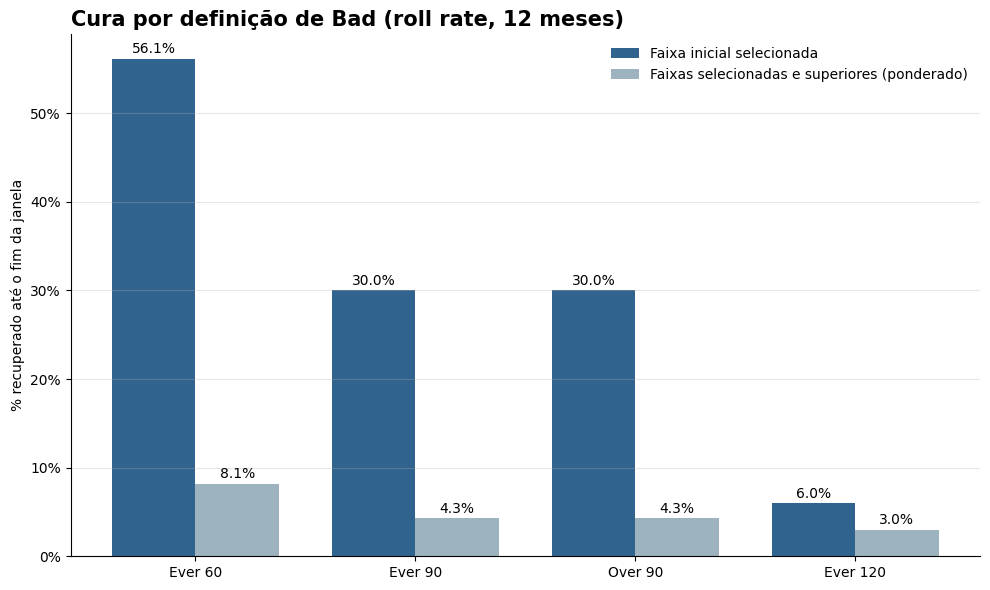

In [22]:

def cura_corte(rr, col_faixa, col_n, col_cura, k):
    t = rr.copy()

    t["idx"] = pd.to_numeric(
        t[col_faixa]
        .astype(str)
        .str.extract(r"^\s*(\d+)", expand=False),
        errors="coerce",
    )

    linha = t.loc[t["idx"] == k]

    if linha.empty:
        raise ValueError(
            f"Faixa k={k} não encontrada. "
            f"Índices disponíveis: "
            f"{sorted(t['idx'].dropna().unique().tolist())}"
        )

    # Cura da faixa selecionada
    logo_acima = linha[col_cura].iloc[0]

    # Cura ponderada da faixa selecionada e das superiores
    acima = t.loc[
        (t["idx"] >= k)
        & t[col_n].notna()
        & t[col_cura].notna()
        & (t[col_n] > 0)
    ]

    ponderado = (
        np.average(
            acima[col_cura],
            weights=acima[col_n],
        )
        if not acima.empty
        else np.nan
    )

    return logo_acima, ponderado


# Colunas de cada definição
E = (
    "faixa_atraso_referencia",
    "total_observacoes",
    "taxa_cura_percentual",
)

O = (
    "faixa_atraso_referencia",
    "total_observacoes",
    "perc_recuperacao_total_cura",
)


# Cenários de comparação
specs = [
    ("Ever 60", roll_rate_ever_12_df, E, 3),
    ("Ever 90", roll_rate_ever_12_df, E, 4),
    ("Over 90", roll_rate_over_12_df, O, 4),
    ("Ever 120", roll_rate_ever_12_df, E, 5),
]


# Calcula os indicadores
resultados = []

for nome, rr, cols, k in specs:
    faixa, todas = cura_corte(rr, *cols, k)

    resultados.append({
        "definicao": nome,
        "faixa_logo_acima": faixa,
        "todas_acima": todas,
    })

cura = pd.DataFrame(resultados).set_index("definicao")

display(cura.round(2))


# Gráfico
fig, ax = plt.subplots(figsize=(10, 6))

pos = np.arange(len(cura))
w = 0.38

b1 = ax.bar(
    pos - w / 2,
    cura["faixa_logo_acima"],
    w,
    color="#30638e",
    label="Faixa inicial selecionada",
)

b2 = ax.bar(
    pos + w / 2,
    cura["todas_acima"],
    w,
    color="#9db4c0",
    label="Faixas selecionadas e superiores (ponderado)",
)

ax.bar_label(b1, fmt="%.1f%%", padding=2)
ax.bar_label(b2, fmt="%.1f%%", padding=2)

ax.set_xticks(pos)
ax.set_xticklabels(cura.index)

ax.set_title(
    "Cura por definição de Bad (roll rate, 12 meses)",
    loc="left",
    fontsize=15,
    fontweight="bold",
)

ax.set_ylabel("% recuperado até o fim da janela")

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=0)
)

ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")

for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.show()


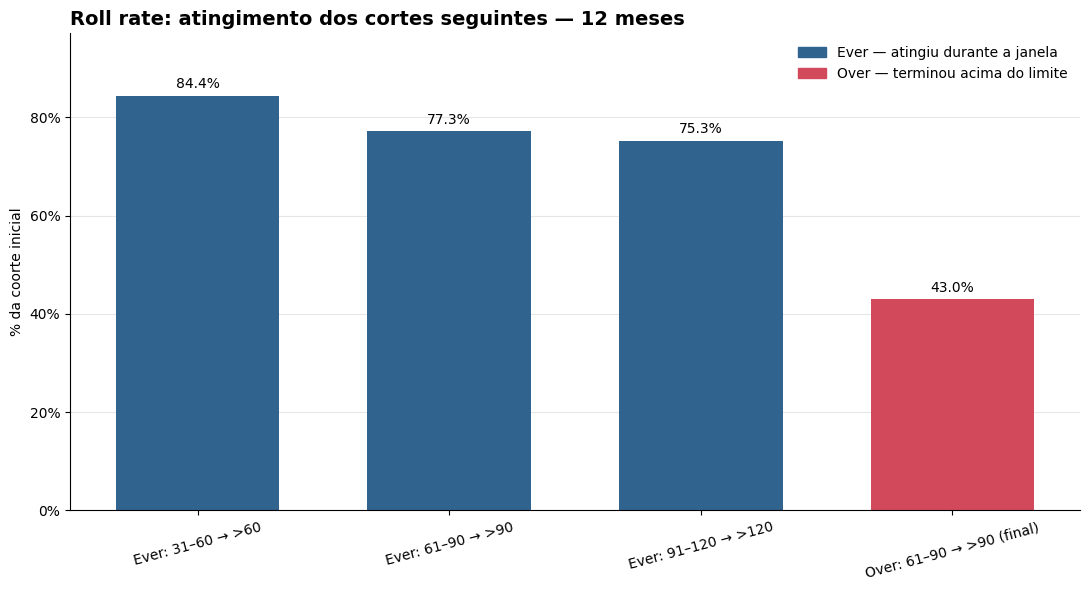

,Transição,Tipo,Percentual
0,Ever: 31–60 → >60,Ever,84.44
1,Ever: 61–90 → >90,Ever,77.29
2,Ever: 91–120 → >120,Ever,75.28
3,Over: 61–90 → >90 (final),Over,42.96


In [26]:


ever = roll_rate_ever_12_df
over = roll_rate_over_12_df


def linha_faixa(df, coluna, indice):
    """Localiza uma faixa pelo índice numérico inicial."""

    idx = pd.to_numeric(
        df[coluna]
        .astype(str)
        .str.extract(r"^\s*(\d+)", expand=False),
        errors="coerce",
    )

    resultado = df.loc[idx == indice]

    if resultado.empty:
        raise ValueError(
            f"Faixa de índice {indice} não encontrada. "
            f"Categorias disponíveis: {df[coluna].tolist()}"
        )

    return resultado.iloc[0]


e_31_60 = linha_faixa(ever, "faixa_atraso_referencia", 2)
e_61_90 = linha_faixa(ever, "faixa_atraso_referencia", 3)
e_91_120 = linha_faixa(ever, "faixa_atraso_referencia", 4)

# Over: coorte inicial de 61–90 dias
o_61_90 = linha_faixa(over, "faixa_atraso_referencia", 3)


# Percentuais de atingimento durante a janela (Ever)
# e percentual em atraso no fechamento da janela (Over).
dados = [
    {
        "Transição": "Ever: 31–60 → >60",
        "Tipo": "Ever",
        "Percentual": e_31_60[
            "taxa_ever_atraso_60d"
        ],
    },
    {
        "Transição": "Ever: 61–90 → >90",
        "Tipo": "Ever",
        "Percentual": e_61_90[
            "taxa_ever_atraso_90d"
        ],
    },
    {
        "Transição": "Ever: 91–120 → >120",
        "Tipo": "Ever",
        "Percentual": e_91_120[
            "taxa_ever_atraso_120d"
        ],
    },
    {
        "Transição": "Over: 61–90 → >90 (final)",
        "Tipo": "Over",
        "Percentual": o_61_90[
            "perc_final_atraso_acima_90"
        ],
    },
]

passagens = pd.DataFrame(dados)


# Gráfico
fig, ax = plt.subplots(figsize=(11, 6))

cores = [
    "#30638e" if tipo == "Ever" else "#d1495b"
    for tipo in passagens["Tipo"]
]

barras = ax.bar(
    passagens["Transição"],
    passagens["Percentual"],
    color=cores,
    width=0.65,
)

ax.bar_label(barras, fmt="%.1f%%", padding=3)

max_valor = passagens["Percentual"].max()
ax.set_ylim(0, min(110, max(10, max_valor * 1.15)))

ax.set_ylabel("% da coorte inicial")
ax.set_title(
    "Roll rate: atingimento dos cortes seguintes — 12 meses",
    loc="left",
    fontsize=14,
    fontweight="bold",
)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=100, decimals=0)
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=15)

ax.legend(
    handles=[
        Patch(color="#30638e", label="Ever — atingiu durante a janela"),
        Patch(color="#d1495b", label="Over — terminou acima do limite"),
    ],
    frameon=False,
)

for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.show()

display(passagens.round(2))


## Conclusão

A definição de Bad adotada é Ever 90 em 12 meses (população até 24/11/2023). 

O Ever 60/12m (7,86%) foi descartado pela alta volatilidade e baixa conversão (29%) para atrasos maiores; o Ever 120/12m (2,35%) por ser restritivo e reduzir a amostra de treino; o Ever 90/9m (3,55%) e o Over 90/12m (2,90%) por capturarem apenas cerca de 70% dos eventos; e o Ever 90/18m (4,60%) por inviabilizar o uso de dados recentes de 2023H2 e 2024.
